c:\Users\Waqar\Desktop\DATA VISUAL\.venv-1\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


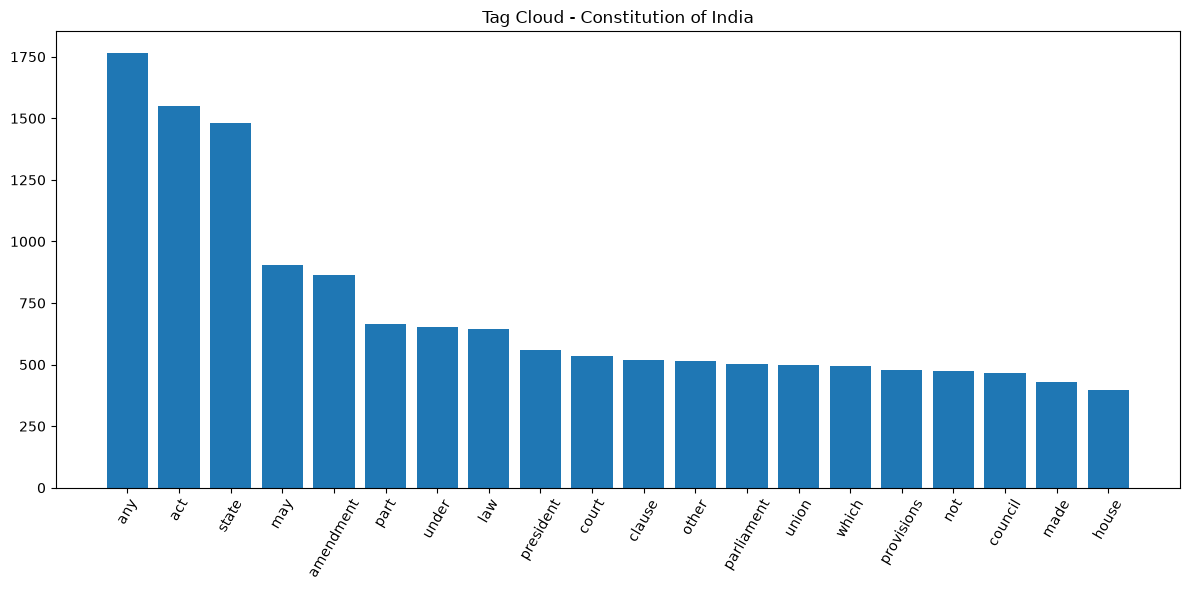

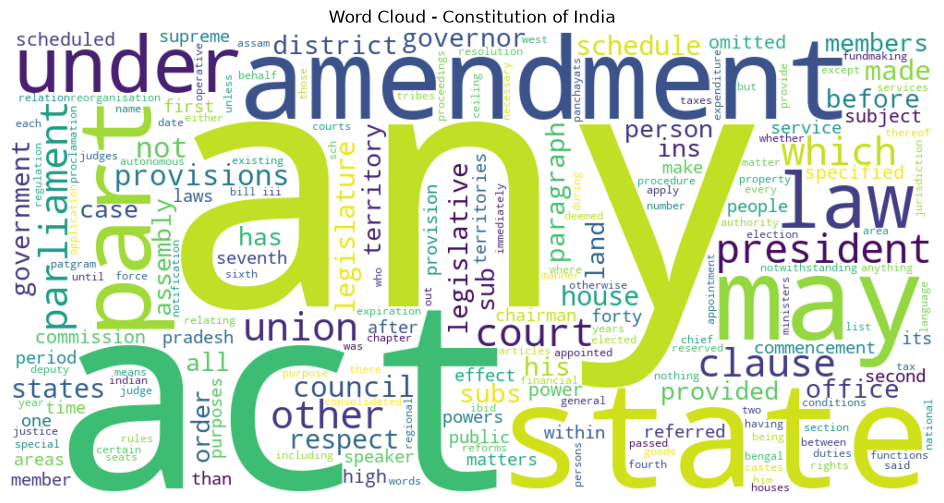

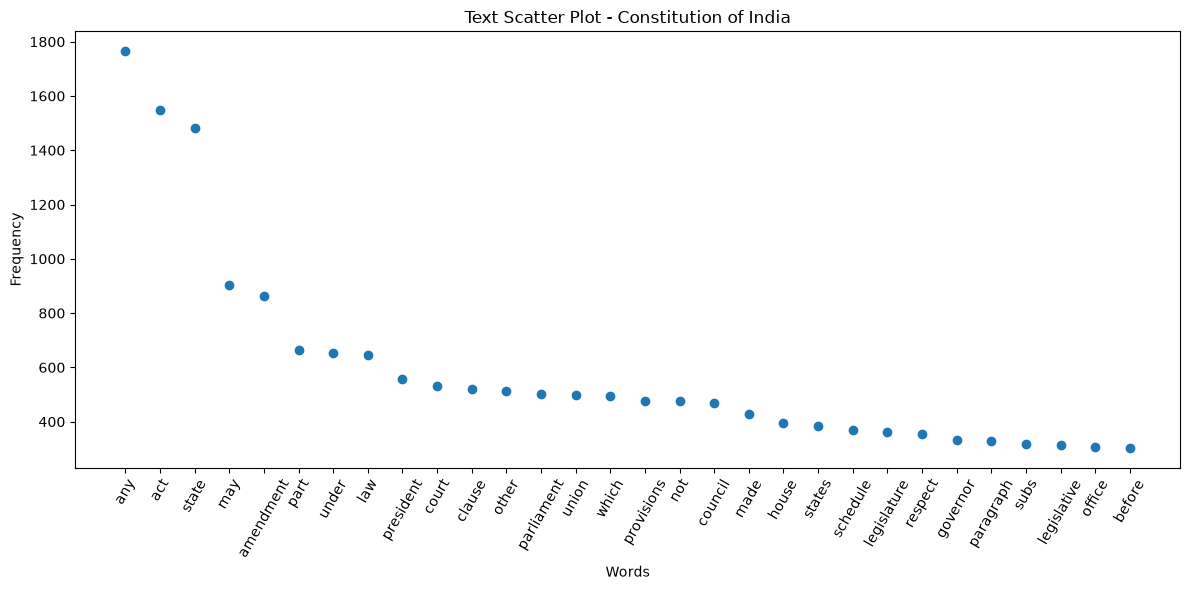

In [1]:
import fitz
import re
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter

# Extract text from PDF
doc = fitz.open("constitution.pdf")
text = " ".join(page.get_text() for page in doc)
words = re.findall(r'\b[a-zA-Z]{3,}\b', text.lower())

# Remove common words
stop = set("""the and for are that this with from shall have
been will into such upon india constitution article""".split())
words = [w for w in words if w not in stop]
freq = Counter(words)

# 1. Tag Cloud
plt.figure(figsize=(12, 6))
top = freq.most_common(20)
plt.bar([w for w, n in top], [n for w, n in top])
plt.xticks(rotation=60)
plt.title("Tag Cloud - Constitution of India")
plt.tight_layout()
plt.show()

# 2. Word Cloud
wc = WordCloud(width=1000, height=500,
               background_color="white").generate_from_frequencies(freq)
plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Constitution of India")
plt.show()

# 3. Text Scatter Plot
top_words = freq.most_common(30)
plt.figure(figsize=(12, 6))
plt.scatter(range(len(top_words)), [n for w, n in top_words])
plt.xticks(range(len(top_words)),
           [w for w, n in top_words], rotation=60)
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.title("Text Scatter Plot - Constitution of India")
plt.tight_layout()
plt.show()
